# Task 3: Model Research, Validation & Comparison
## Credit Card Fraud Detection

**Objective:** Build and compare three machine learning models on the dataset prepared in Task 2, validate and tune them fairly, report suitable results, and save the selected model together with its preprocessing.

**Workflow:** Research → Pipeline → Default Baselines → Validation → Tuning → Comparison → Save

| Section | Content |
|---|---|
| 00 | Setup and reuse of the Task 1 / Task 2 data preparation |
| 01 | Model research & selection |
| 02 | ML pipelines & default baselines |
| 03 | Pre-validation & stratified cross-validation |
| 04 | Hyperparameter tuning |
| 05 | Metrics & diagnostic results |
| 06 | Comparison & best-model selection |
| 07 | Final evaluation on the untouched test set, save & reload |

### How Task 1 and Task 2 are reused

This notebook does **not** redo the earlier tasks. It reuses their decisions:

| Source | Decision reused in Task 3 |
|---|---|
| Task 1 (`Fraud_Detection_EDA.ipynb`) | Same raw files `archive/fraudTrain.csv` and `archive/fraudTest.csv`; target `is_fraud`; strong class imbalance, so accuracy alone is not enough; `amt` outliers are kept. |
| Task 2 (`Task2.ipynb`) | Same `create_features()` function (`trans_hour`, `trans_day`, `customer_age`, `distance_km`), same dropped identifier / personal columns, same 17 input features (11 numerical + 6 categorical), same preprocessing (median imputation + `StandardScaler` for numerical, most-frequent imputation + `OneHotEncoder(handle_unknown="ignore")` for categorical), and the original train / test split. |

**One deliberate change:** Task 2 fitted the preprocessor once on the whole training set. Task 3 requires the preprocessing to be **re-fitted inside every cross-validation fold** (leakage rule). Therefore the same preprocessing *definition* is rebuilt here and placed inside a scikit-learn `Pipeline` together with each estimator, instead of loading the already-fitted Task 2 preprocessor.

The test set (`fraudTest.csv`) is kept untouched until Section 07 and is used exactly once.

## 00 Setup

### 0.1 Import Libraries and Set Global Configuration

All random seeds are fixed with `RANDOM_STATE = 42` so that subsampling, cross-validation folds, searches and models are reproducible.

In [1]:
import os
import json
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import lightgbm

from scipy.stats import loguniform, uniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=UserWarning)

# Reproducibility and output location
RANDOM_STATE = 42
OUTPUT_DIR = "task3_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Consistent plot style: one fixed colour per model (never cycled)
MODEL_COLORS = {
    "Logistic Regression": "#2a78d6",   # blue
    "Random Forest": "#eb6834",         # orange
    "LightGBM": "#1baf7a",              # aqua
}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
})

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("lightgbm    :", lightgbm.__version__)

Python      : 3.13.18
pandas      : 3.0.5
scikit-learn: 1.9.1
lightgbm    : 4.7.0


### 0.2 Load the Data and Apply the Task 2 Feature Engineering

The function `create_features()` and the list of dropped columns are copied unchanged from Task 2 so that Task 3 uses exactly the same feature definitions.

In [2]:
# Load the same raw files used in Task 1 and Task 2
df_train = pd.read_csv("archive/fraudTrain.csv")
df_test = pd.read_csv("archive/fraudTest.csv")

print("Raw Train Shape:", df_train.shape)
print("Raw Test Shape :", df_test.shape)


def create_features(df):
    """Task 2 feature engineering (unchanged): time, age and distance features."""
    df = df.copy()

    # Convert dates
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])

    # Transaction time features
    df["trans_hour"] = df["trans_date_trans_time"].dt.hour
    df["trans_day"] = df["trans_date_trans_time"].dt.dayofweek

    # Customer age at transaction time
    df["customer_age"] = (
        df["trans_date_trans_time"].dt.year
        - df["dob"].dt.year
        - (
            (df["trans_date_trans_time"].dt.month * 100
             + df["trans_date_trans_time"].dt.day)
            < (df["dob"].dt.month * 100 + df["dob"].dt.day)
        )
    )

    # Haversine distance between customer and merchant (km)
    lat1, lon1 = np.radians(df["lat"]), np.radians(df["long"])
    lat2, lon2 = np.radians(df["merch_lat"]), np.radians(df["merch_long"])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    a = np.clip(a, 0, 1)
    df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

    return df


# Identifiers, personal information and redundant time columns removed in Task 2
DROP_COLUMNS = [
    "Unnamed: 0", "cc_num", "trans_num", "first", "last",
    "street", "trans_date_trans_time", "dob", "unix_time",
]
TARGET = "is_fraud"


def prepare_features(df_raw):
    """Raw transactions -> the 17 Task 2 input features (+ target if present)."""
    df = create_features(df_raw).drop(columns=DROP_COLUMNS)
    for col in ["trans_hour", "trans_day", "customer_age", "distance_km"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")   # Task 2, step 3.4
    return df


train_df = prepare_features(df_train)
test_df = prepare_features(df_test)

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]
X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("\nX_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)
print("Same feature columns:", X_train.columns.equals(X_test.columns))

Raw Train Shape: (1296675, 23)
Raw Test Shape : (555719, 23)



X_train: (1296675, 17) | y_train: (1296675,)
X_test : (555719, 17) | y_test : (555719,)
Same feature columns: True


### 0.3 Feature Groups and Class Balance

Numerical and categorical features are identified exactly as in Task 2 (step 3.4): 11 numerical and 6 categorical features.

In [3]:
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print(f"Numerical features ({len(numerical_features)}):", numerical_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)

# Class balance (training data only)
balance = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Percent": (y_train.value_counts(normalize=True).sort_index() * 100).round(3),
})
balance.index = ["Legitimate (0)", "Fraud (1)"]
display(balance)

majority_accuracy = 1 - y_train.mean()
print(f"Accuracy of always predicting 'legitimate': {majority_accuracy:.4%}")

Numerical features (11): ['amt', 'zip', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'trans_hour', 'trans_day', 'customer_age', 'distance_km']
Categorical features (6): ['merchant', 'category', 'gender', 'city', 'state', 'job']


,Count,Percent
Legitimate (0),1289169,99.421
Fraud (1),7506,0.579


Accuracy of always predicting 'legitimate': 99.4211%


The fraud class is only about **0.58 %** of the training transactions. A model that never predicts fraud already reaches about **99.4 % accuracy**, so accuracy cannot be the main evaluation metric.

## 01 Model Research & Selection

### 1.1 Identify the Task

- **Learning problem:** supervised **binary classification**. The target `is_fraud` is either 0 (legitimate) or 1 (fraud).
- **Main difficulty:** strong class imbalance (about 1 fraud in 172 transactions).
- **Main evaluation goal:** rank fraudulent transactions above legitimate ones and catch as many frauds as possible without flooding analysts with false alarms.
- **Main metric:** **Average Precision (PR-AUC)** of the fraud class. It summarises the whole precision–recall curve, does not depend on one decision threshold, and is not inflated by the large number of true negatives (unlike accuracy and, to a lesser degree, ROC-AUC).
- **Supporting metrics:** Precision, Recall and F1-score for the fraud class, ROC-AUC, Accuracy and the Confusion Matrix.

### 1.2 Research of Three Suitable Algorithms

Three algorithms from **different model families** were chosen so that the comparison is informative.

**1. Logistic Regression (linear model)**
Models the log-odds of fraud as a weighted sum of the features and passes it through the sigmoid function to produce a probability. It is trained by minimising the regularised log-loss.
*Why it suits this dataset:* it is a fast and interpretable baseline that works directly on the large sparse one-hot matrix (about 2,000 columns) produced by the Task 2 preprocessing. `class_weight="balanced"` can compensate for the class imbalance. Its limitation is that it can only draw a linear boundary, while fraud depends on interactions (for example a high amount *at night* in certain categories).

**2. Random Forest (bagging ensemble of decision trees)**
Builds many decision trees on bootstrap samples of the data, each split using a random subset of features, and averages their probability votes.
*Why it suits this dataset:* trees learn non-linear thresholds and feature interactions automatically (amount × hour × category), they are robust to outliers in `amt` (which Task 1 decided to keep) and to scaling, and averaging many trees reduces variance. Limitations: slower to train on 1.3 M rows and large model files.

**3. LightGBM (gradient-boosted decision trees)**
Builds shallow trees **sequentially**; each new tree fits the gradient of the loss of the current ensemble, so it corrects the errors of the previous trees. LightGBM uses histogram-based, leaf-wise tree growth and natively supports sparse input.
*Why it suits this dataset:* gradient boosting is a state-of-the-art method for tabular data and fraud detection, it is fast on large data, and it offers explicit controls for imbalance (`scale_pos_weight`) and over-fitting (learning rate, number of leaves, regularisation). Limitation: more hyperparameters and higher sensitivity to their values.

### 1.3 Research Summary Table

In [4]:
research_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Family": "Linear model",
        "Reason for choosing": "Fast, interpretable baseline; handles the sparse one-hot matrix; class_weight for imbalance",
        "Strengths": "Simple, fast, calibrated probabilities, coefficients are interpretable",
        "Limitations": "Linear decision boundary; cannot learn feature interactions by itself",
        "Key hyperparameters": "C, penalty, class_weight, solver, max_iter",
        "Reference": "https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression",
    },
    {
        "Model": "Random Forest",
        "Family": "Bagging ensemble of trees",
        "Reason for choosing": "Captures non-linear patterns and interactions; robust to outliers and scaling",
        "Strengths": "Low variance, little tuning needed, feature importances",
        "Limitations": "Slow on large data, large model files, probabilities less calibrated",
        "Key hyperparameters": "n_estimators, max_depth, min_samples_leaf, max_features, class_weight",
        "Reference": "https://scikit-learn.org/stable/modules/ensemble.html#random-forests ; Breiman (2001), Machine Learning 45:5-32",
    },
    {
        "Model": "LightGBM",
        "Family": "Gradient-boosted trees",
        "Reason for choosing": "State of the art on tabular data; fast; native sparse input; imbalance controls",
        "Strengths": "High accuracy, fast training, regularisation options, feature importances",
        "Limitations": "Many hyperparameters; can over-fit or become unstable if poorly tuned",
        "Key hyperparameters": "n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda, scale_pos_weight",
        "Reference": "https://lightgbm.readthedocs.io/en/latest/Parameters.html ; Ke et al. (2017), NeurIPS",
    },
])

display(research_summary.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
research_summary.to_csv(f"{OUTPUT_DIR}/research_summary.csv", index=False)

,Model,Family,Reason for choosing,Strengths,Limitations,Key hyperparameters,Reference
0,Logistic Regression,Linear model,"Fast, interpretable baseline; handles the sparse one-hot matrix; class_weight for imbalance","Simple, fast, calibrated probabilities, coefficients are interpretable",Linear decision boundary; cannot learn feature interactions by itself,"C, penalty, class_weight, solver, max_iter",https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
1,Random Forest,Bagging ensemble of trees,Captures non-linear patterns and interactions; robust to outliers and scaling,"Low variance, little tuning needed, feature importances","Slow on large data, large model files, probabilities less calibrated","n_estimators, max_depth, min_samples_leaf, max_features, class_weight","https://scikit-learn.org/stable/modules/ensemble.html#random-forests ; Breiman (2001), Machine Learning 45:5-32"
2,LightGBM,Gradient-boosted trees,State of the art on tabular data; fast; native sparse input; imbalance controls,"High accuracy, fast training, regularisation options, feature importances",Many hyperparameters; can over-fit or become unstable if poorly tuned,"n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda, scale_pos_weight","https://lightgbm.readthedocs.io/en/latest/Parameters.html ; Ke et al. (2017), NeurIPS"


## 02 Build Pipelines & Default Baselines

### 2.1 Build the ML Pipelines

Each model is wrapped in one `Pipeline`:

`ColumnTransformer` (Task 2 preprocessing) → estimator

- The preprocessing definition is **identical for all three models** (same features, same transforms).
- Scaling is not required by the tree models, but it does not change tree splits, so keeping one shared preprocessing keeps the comparison fair and simple.
- **Leakage rule:** because the preprocessing is a step of the pipeline, `fit()` learns the imputation medians, the scaler statistics and the one-hot categories **only from the training folds** in every CV split. Nothing is pre-processed on the whole dataset beforehand.

In [5]:
def build_preprocessor():
    """Exact Task 2 preprocessing definition (unfitted)."""
    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
    ])
    return ColumnTransformer([
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ])


def build_pipeline(estimator):
    """Preprocessing + estimator in a single, leakage-safe pipeline."""
    return Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", estimator),
    ])


# Default hyperparameters; only essential settings are changed:
#   - random_state for reproducibility
#   - max_iter=1000 so that the lbfgs solver can converge on ~2,000 features
#   - n_jobs to use the available CPU cores, verbose=-1 to silence LightGBM logs
default_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
}

default_pipelines = {name: build_pipeline(est) for name, est in default_models.items()}
default_pipelines["LightGBM"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

### 2.2 Validation Plan and Development Sample

**Validation design:** K-fold cross-validation on training data only, with the original test file kept untouched.

**Compute constraint:** the training file has 1,296,675 rows. Running 5-fold CV for three models *plus* randomized searches on all rows would require several hundred full fits (Random Forest alone takes minutes per fit). Therefore:

1. Model **development** (baselines, CV and tuning) uses a **stratified random subsample of 250,000 training rows** (`dev` set). Stratification keeps the original fraud rate.
2. The **final selected pipeline is re-fitted on all 1,296,675 training rows** in Section 07.
3. The test set is never used for development decisions.

The subsample is drawn from the training data only, so no test information is involved.

In [6]:
DEV_SIZE = 250_000

X_dev, _, y_dev, _ = train_test_split(
    X_train, y_train,
    train_size=DEV_SIZE,
    stratify=y_train,
    random_state=RANDOM_STATE,
)
X_dev = X_dev.reset_index(drop=True)
y_dev = y_dev.reset_index(drop=True)

print("Development sample:", X_dev.shape)
print(f"Fraud rate - full train: {y_train.mean():.4%} | dev sample: {y_dev.mean():.4%}")
print("Fraud cases in dev sample:", int(y_dev.sum()))

Development sample: (250000, 17)
Fraud rate - full train: 0.5789% | dev sample: 0.5788%
Fraud cases in dev sample: 1447


### 2.3 Cross-Validation Strategy and Evaluation Helper

- **Strategy:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Stratification guarantees that every fold has the same fraud rate (about 290 fraud cases per validation fold). The **same fold object** is used for every model, for the baselines and for the tuning, so all numbers are directly comparable.
- **Helper `evaluate_cv()`:** for each fold it clones the pipeline, fits it on the training folds (so preprocessing is refitted per fold), measures training time, and computes the metrics on both the training folds and the validation fold. It also stores the **out-of-fold (OOF) predicted probabilities**, i.e. a validation prediction for every dev row, which are kept for diagnostics and later comparison.
- Threshold-based metrics (precision, recall, F1, accuracy, confusion matrix) use the default threshold of 0.5 during model comparison.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
MAIN_METRIC = "avg_precision"


def compute_metrics(y_true, y_proba, threshold=0.5):
    """All classification metrics used in this notebook (fraud = positive class)."""
    y_pred = (y_proba >= threshold).astype(int)
    return {
        "avg_precision": average_precision_score(y_true, y_proba),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }


def evaluate_cv(name, pipeline, X, y, cv):
    """Manual stratified K-fold CV with per-fold refitting of the whole pipeline."""
    fold_rows = []
    oof_proba = np.zeros(len(y))

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, y), start=1):
        model = clone(pipeline)

        start = time.perf_counter()
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        fit_time = time.perf_counter() - start

        train_proba = model.predict_proba(X.iloc[tr_idx])[:, 1]
        val_proba = model.predict_proba(X.iloc[va_idx])[:, 1]
        oof_proba[va_idx] = val_proba

        row = {"model": name, "fold": fold, "fit_time_s": fit_time}
        row.update({f"train_{k}": v for k, v in compute_metrics(y.iloc[tr_idx], train_proba).items()})
        row.update({f"val_{k}": v for k, v in compute_metrics(y.iloc[va_idx], val_proba).items()})
        fold_rows.append(row)

    folds = pd.DataFrame(fold_rows)
    print(f"{name:<20} val {MAIN_METRIC} = {folds['val_' + MAIN_METRIC].mean():.4f} "
          f"± {folds['val_' + MAIN_METRIC].std():.4f} | mean fit time {folds['fit_time_s'].mean():.1f}s")
    return {"folds": folds, "oof_proba": oof_proba}


def summarize(results, metrics=("avg_precision", "roc_auc", "f1", "precision", "recall", "accuracy")):
    """Mean ± std across folds for each model."""
    rows = []
    for name, res in results.items():
        f = res["folds"]
        row = {"Model": name}
        for m in metrics:
            row[f"val_{m}"] = f"{f['val_' + m].mean():.4f} ± {f['val_' + m].std():.4f}"
        row["train_avg_precision"] = f"{f['train_avg_precision'].mean():.4f}"
        row["fit_time_s"] = round(f["fit_time_s"].mean(), 2)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

### 2.4 Train with Default Hyperparameters and Record the Baselines

Each default pipeline is evaluated with the 5-fold CV defined above. For every model we record:

- the baseline settings (`get_params()` of the estimator),
- the training time per fold,
- the initial validation metrics,
- the out-of-fold predictions (stored in `baseline_results[...]["oof_proba"]`).

In [8]:
baseline_results = {}
for name, pipe in default_pipelines.items():
    baseline_results[name] = evaluate_cv(name, pipe, X_dev, y_dev, cv)

# Baseline settings (only parameters relevant for later tuning are shown)
key_params = {
    "Logistic Regression": ["C", "class_weight", "solver", "max_iter"],
    "Random Forest": ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"],
    "LightGBM": ["n_estimators", "learning_rate", "num_leaves", "min_child_samples",
                 "subsample", "colsample_bytree", "reg_lambda", "scale_pos_weight"],
}
# LightGBM only lists scale_pos_weight in get_params() once it is set explicitly;
# its documented library default is 1.0.
LIBRARY_DEFAULTS = {"scale_pos_weight": 1.0}


def get_settings(estimator, names):
    params = estimator.get_params()
    return {p: params.get(p, LIBRARY_DEFAULTS.get(p)) for p in names}


baseline_settings = {name: get_settings(default_models[name], key_params[name]) for name in default_models}
for name, params in baseline_settings.items():
    print(f"{name}: {params}")

# Keep the baseline OOF predictions for later comparison
baseline_oof = pd.DataFrame({name: res["oof_proba"] for name, res in baseline_results.items()})
baseline_oof["is_fraud"] = y_dev.values
baseline_oof.head()

Logistic Regression  val avg_precision = 0.2243 ± 0.0269 | mean fit time 1.2s


Random Forest        val avg_precision = 0.7921 ± 0.0266 | mean fit time 18.9s


LightGBM             val avg_precision = 0.6483 ± 0.1955 | mean fit time 1.8s
Logistic Regression: {'C': 1.0, 'class_weight': None, 'solver': 'lbfgs', 'max_iter': 1000}
Random Forest: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None}
LightGBM: {'n_estimators': 100, 'learning_rate': 0.1, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 0.0, 'scale_pos_weight': 1.0}


,Logistic Regression,Random Forest,LightGBM,is_fraud
0,0.000002,0.0,0.000004,0
1,0.003205,0.0,0.025440,0
2,0.003699,0.0,0.000038,0
3,0.002395,0.0,0.000038,0
4,0.001763,0.0,0.000021,0


## 03 Pre-Validation & Cross-Validation

### 3.1 Cross-Validation Results of the Default Models

All three default models were evaluated with the **same** stratified 5-fold split. Results are reported as **mean ± standard deviation across the 5 folds**.

In [9]:
baseline_summary = summarize(baseline_results)
display(baseline_summary)
baseline_summary.to_csv(f"{OUTPUT_DIR}/baseline_cv_summary.csv")

# Fold-level details
baseline_folds = pd.concat([r["folds"] for r in baseline_results.values()], ignore_index=True)
baseline_folds.to_csv(f"{OUTPUT_DIR}/baseline_cv_folds.csv", index=False)
display(baseline_folds[["model", "fold", "fit_time_s", "train_avg_precision",
                        "val_avg_precision", "val_f1", "val_recall"]].round(4))

,val_avg_precision,val_roc_auc,val_f1,val_precision,val_recall,val_accuracy,train_avg_precision,fit_time_s
Model,,,,,,,,
Logistic Regression,0.2243 ± 0.0269,0.8284 ± 0.0145,0.0799 ± 0.0276,0.3718 ± 0.0699,0.0449 ± 0.0163,0.9941 ± 0.0001,0.3318,1.24
Random Forest,0.7921 ± 0.0266,0.9528 ± 0.0096,0.6663 ± 0.0237,0.9877 ± 0.0058,0.5031 ± 0.0265,0.9971 ± 0.0002,1.0000,18.91
LightGBM,0.6483 ± 0.1955,0.9602 ± 0.0392,0.7223 ± 0.0879,0.7427 ± 0.1467,0.7104 ± 0.0453,0.9968 ± 0.0013,0.8466,1.83


,model,fold,fit_time_s,train_avg_precision,val_avg_precision,val_f1,val_recall
0,Logistic Regression,1,1.1304,0.3376,0.2028,0.0625,0.0346
1,Logistic Regression,2,1.3245,0.3325,0.2321,0.0982,0.0554
2,Logistic Regression,3,1.3212,0.3300,0.2158,0.0446,0.0242
3,Logistic Regression,4,1.1926,0.3393,0.2032,0.0802,0.0448
4,Logistic Regression,5,1.2418,0.3195,0.2674,0.1141,0.0655
5,Random Forest,1,18.5531,1.0000,0.7664,0.6417,0.4740
6,Random Forest,2,19.0609,1.0000,0.8157,0.6996,0.5398
7,Random Forest,3,18.5103,1.0000,0.7963,0.6559,0.4913
8,Random Forest,4,19.5784,1.0000,0.7628,0.6529,0.4897
9,Random Forest,5,18.8579,1.0000,0.8192,0.6817,0.5207


### 3.2 Check Generalization: Training vs. Validation

The gap between training-fold and validation-fold Average Precision shows under- or over-fitting; the spread across folds shows stability.

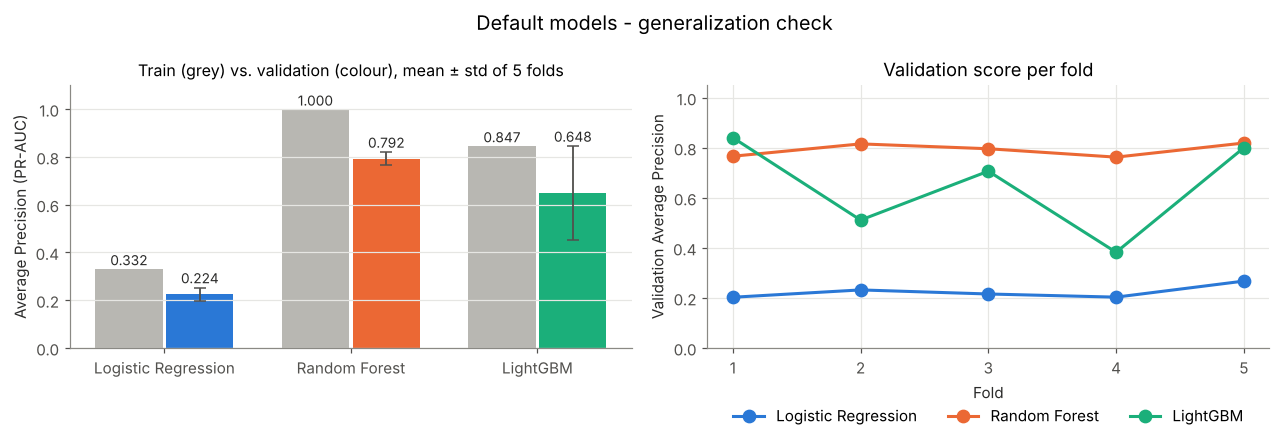

,train_AP,val_AP,gap (train - val),val_AP std
Logistic Regression,0.3318,0.2243,0.1075,0.0269
Random Forest,1.0000,0.7921,0.2079,0.0266
LightGBM,0.8466,0.6483,0.1983,0.1955


In [10]:
def plot_train_vs_val(results, title):
    names = list(results)
    x = np.arange(len(names))
    width = 0.36
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    # Left: mean train vs validation main metric
    train_means = [results[n]["folds"]["train_avg_precision"].mean() for n in names]
    val_means = [results[n]["folds"]["val_avg_precision"].mean() for n in names]
    val_stds = [results[n]["folds"]["val_avg_precision"].std() for n in names]
    axes[0].bar(x - width / 2 - 0.01, train_means, width, color="#b8b7b2")
    axes[0].bar(x + width / 2 + 0.01, val_means, width, yerr=val_stds, capsize=4,
                color=[MODEL_COLORS[n] for n in names], error_kw={"ecolor": "#52514e", "elinewidth": 1.2})
    for i, (t, v, sd) in enumerate(zip(train_means, val_means, val_stds)):
        axes[0].text(i - width / 2 - 0.01, t + 0.015, f"{t:.3f}", ha="center", fontsize=9, color="#2b2b2a")
        axes[0].text(i + width / 2 + 0.01, v + sd + 0.02, f"{v:.3f}", ha="center", fontsize=9, color="#2b2b2a")
    axes[0].set_xticks(x, names)
    axes[0].set_ylim(0, 1.1)
    axes[0].set_ylabel("Average Precision (PR-AUC)")
    axes[0].set_title("Train (grey) vs. validation (colour), mean ± std of 5 folds", fontsize=10.5)
    axes[0].grid(axis="x", visible=False)

    # Right: per-fold validation scores (stability)
    for n in names:
        f = results[n]["folds"]
        axes[1].plot(f["fold"], f["val_avg_precision"], marker="o", markersize=8,
                     color=MODEL_COLORS[n], label=n)
    axes[1].set_xticks(range(1, 6))
    axes[1].set_xlabel("Fold")
    axes[1].set_ylabel("Validation Average Precision")
    axes[1].set_ylim(0, 1.05)
    axes[1].set_title("Validation score per fold")
    axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


plot_train_vs_val(baseline_results, "Default models - generalization check")

gap = pd.DataFrame({
    n: {
        "train_AP": r["folds"]["train_avg_precision"].mean(),
        "val_AP": r["folds"]["val_avg_precision"].mean(),
        "gap (train - val)": r["folds"]["train_avg_precision"].mean() - r["folds"]["val_avg_precision"].mean(),
        "val_AP std": r["folds"]["val_avg_precision"].std(),
    } for n, r in baseline_results.items()
}).T.round(4)
display(gap)

### 3.3 Interpretation of the Default Baselines

- **Logistic Regression - underfitting.** Validation AP is only about **0.22** and training AP is also low (about 0.33). At threshold 0.5 it catches less than 5 % of frauds. A linear boundary on the one-hot features cannot express the non-linear patterns of fraud (e.g. high amount *and* night time *and* certain categories).
- **Random Forest - strong but overfitting.** Validation AP is about **0.79 ± 0.03** and stable across folds, but training AP is **1.00**. Fully grown trees memorise the training folds. At threshold 0.5 it is very precise (about 99 %) but catches only about half of the frauds.
- **LightGBM (defaults) - unstable.** Mean validation AP is about **0.65**, but the fold standard deviation is very large (**± 0.20**; single folds range from about 0.38 to 0.84). Even the *training* AP collapses on some folds. With the default learning rate of 0.1 and only about 1,150 fraud rows per training fold, the boosting is numerically unstable on this extremely imbalanced data. It needs tuning more than the other models do.

These default results are the fixed reference for the tuning step.

## 04 Hyperparameter Tuning

### 4.1 Search Spaces and Reasoning

Tuning starts only after the default baselines were recorded. A small, sensible search space was chosen for each algorithm based on the documentation and common practice for imbalanced tabular data:

| Model | Tuned parameters | Why |
|---|---|---|
| Logistic Regression | `C` (1e-3 – 1e2, log scale), `class_weight` (None / balanced) | `C` controls regularisation strength on ~2,000 sparse one-hot columns; `class_weight` re-weights the rare fraud class. |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` | Number and depth of trees control variance and over-fitting; `max_features` controls tree diversity; `balanced_subsample` handles imbalance per bootstrap. |
| LightGBM | `n_estimators`, `learning_rate`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda`, `scale_pos_weight` | Learning rate × number of trees sets the boosting budget; leaves / min child samples control complexity; row/column subsampling and L2 regularisation reduce over-fitting; `scale_pos_weight` up-weights the fraud class. |

**Search method:** `RandomizedSearchCV` (random sampling is more efficient than an exhaustive grid for these spaces).
- Uses the **same 5 stratified folds** and the **same main metric (`average_precision`)** as the baselines.
- Runs on the **development (training) sample only** - the test set is never touched.
- The preprocessing is part of the searched pipeline, so it is refitted inside every fold.

In [11]:
search_spaces = {
    "Logistic Regression": {
        "model__C": loguniform(1e-3, 1e2),
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 20, 30],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.03],
        "model__class_weight": [None, "balanced_subsample"],
    },
    "LightGBM": {
        "model__n_estimators": [200, 400, 800],
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__num_leaves": [15, 31, 63, 127],
        "model__min_child_samples": [10, 20, 50, 100],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__subsample_freq": [1],
        "model__colsample_bytree": [0.3, 0.5, 0.8, 1.0],
        "model__reg_lambda": [0.0, 1.0, 5.0, 10.0],
        "model__scale_pos_weight": [1, 3, 10, 30],
    },
}

# Number of sampled candidates (bounded by the cost of one fit)
n_iter = {"Logistic Regression": 12, "Random Forest": 8, "LightGBM": 15}

### 4.2 Run the Randomized Searches

In [12]:
searches = {}
search_times = {}

for name, pipe in default_pipelines.items():
    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=search_spaces[name],
        n_iter=n_iter[name],
        scoring="average_precision",
        cv=cv,                     # same folds as the baselines
        refit=False,               # final refit happens later on the full training set
        random_state=RANDOM_STATE,
        n_jobs=1,                  # models themselves use all cores
        error_score="raise",
    )
    start = time.perf_counter()
    search.fit(X_dev, y_dev)
    search_times[name] = time.perf_counter() - start
    searches[name] = search
    print(f"{name:<20} best CV AP = {search.best_score_:.4f} "
          f"(search time {search_times[name] / 60:.1f} min)")
    print("   best params:", {k.replace('model__', ''): v for k, v in search.best_params_.items()})

Logistic Regression  best CV AP = 0.2380 (search time 2.2 min)
   best params: {'C': np.float64(0.16949768237884735), 'class_weight': None}


Random Forest        best CV AP = 0.8087 (search time 16.1 min)
   best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.03, 'max_depth': None, 'class_weight': None}


LightGBM             best CV AP = 0.8882 (search time 8.5 min)
   best params: {'colsample_bytree': 0.8, 'learning_rate': np.float64(0.03313073862781126), 'min_child_samples': 100, 'n_estimators': 800, 'num_leaves': 31, 'reg_lambda': 1.0, 'scale_pos_weight': 10, 'subsample': 0.85, 'subsample_freq': 1}


### 4.3 Top Candidates of Each Search

In [13]:
for name, search in searches.items():
    res = pd.DataFrame(search.cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_fit_time"]
    top = res.sort_values("rank_test_score")[cols].head(5).copy()
    for c in cols:
        if c.startswith("param_"):   # show None explicitly instead of NaN
            top[c] = top[c].apply(lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else v)
    top.columns = [c.replace("param_model__", "") for c in top.columns]
    print(f"\n{name} - top 5 of {len(res)} candidates")
    display(top.round(4))
    res.to_csv(f"{OUTPUT_DIR}/search_results_{name.replace(' ', '_').lower()}.csv", index=False)


Logistic Regression - top 5 of 12 candidates


,C,class_weight,mean_test_score,std_test_score,mean_fit_time
3,0.1695,None,0.2380,0.0221,1.2709
0,0.0746,None,0.2338,0.0240,1.1119
11,1.1436,None,0.2283,0.0249,1.4144
2,0.9847,None,0.2244,0.0205,1.5052
9,0.0010,balanced,0.1997,0.0172,1.2355



Random Forest - top 5 of 8 candidates


,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_score,std_test_score,mean_fit_time
1,200,1,0.03,None,None,0.8087,0.0228,38.4694
5,200,2,0.03,None,balanced_subsample,0.7810,0.0284,32.0111
2,200,2,sqrt,None,None,0.7735,0.0268,30.0386
4,300,4,sqrt,None,balanced_subsample,0.7287,0.0334,40.7448
7,100,1,0.03,30,None,0.7166,0.0327,7.0485



LightGBM - top 5 of 15 candidates


,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,scale_pos_weight,subsample,subsample_freq,mean_test_score,std_test_score,mean_fit_time
4,0.8,0.0331,100,800,31,1.0,10,0.85,1,0.8882,0.0122,7.6260
14,0.8,0.0181,100,800,63,0.0,10,0.70,1,0.8835,0.0122,10.8491
5,0.8,0.0314,100,200,63,0.0,10,1.00,1,0.8810,0.0166,3.1422
11,0.8,0.0476,20,200,127,0.0,3,1.00,1,0.8798,0.0139,4.1995
1,0.5,0.0160,50,800,127,0.0,30,1.00,1,0.8792,0.0147,11.9066


### 4.4 Re-evaluate the Tuned Pipelines with the Same CV Procedure

To compare default and tuned models with **exactly the same evaluation criteria**, the best configuration of each search is evaluated again with `evaluate_cv()` on the same five folds. This gives train/validation metrics, timing and out-of-fold predictions for the tuned models.

In [14]:
tuned_pipelines = {
    name: clone(default_pipelines[name]).set_params(**searches[name].best_params_)
    for name in default_pipelines
}

tuned_results = {}
for name, pipe in tuned_pipelines.items():
    tuned_results[name] = evaluate_cv(name, pipe, X_dev, y_dev, cv)

tuned_settings = {
    name: get_settings(tuned_pipelines[name].named_steps["model"], key_params[name])
    for name in tuned_pipelines
}
tuned_summary = summarize(tuned_results)
display(tuned_summary)
tuned_summary.to_csv(f"{OUTPUT_DIR}/tuned_cv_summary.csv")

Logistic Regression  val avg_precision = 0.2380 ± 0.0248 | mean fit time 1.1s


Random Forest        val avg_precision = 0.8087 ± 0.0255 | mean fit time 38.1s


LightGBM             val avg_precision = 0.8882 ± 0.0137 | mean fit time 7.5s


,val_avg_precision,val_roc_auc,val_f1,val_precision,val_recall,val_accuracy,train_avg_precision,fit_time_s
Model,,,,,,,,
Logistic Regression,0.2380 ± 0.0248,0.8235 ± 0.0129,0.0167 ± 0.0098,0.1203 ± 0.0741,0.0090 ± 0.0053,0.9939 ± 0.0001,0.2802,1.15
Random Forest,0.8087 ± 0.0255,0.9610 ± 0.0080,0.6965 ± 0.0311,0.9911 ± 0.0034,0.5377 ± 0.0373,0.9973 ± 0.0002,1.0000,38.09
LightGBM,0.8882 ± 0.0137,0.9946 ± 0.0021,0.8375 ± 0.0113,0.8811 ± 0.0180,0.7989 ± 0.0268,0.9982 ± 0.0001,1.0000,7.47


### 4.5 Default vs. Tuned Performance

,Model,Version,val_AP_mean,val_AP_std,val_ROC_AUC,val_F1,val_Precision,val_Recall,train_AP,fit_time_s
0,Logistic Regression,Default,0.2243,0.0269,0.8284,0.0799,0.3718,0.0449,0.3318,1.2421
1,Logistic Regression,Tuned,0.2380,0.0248,0.8235,0.0167,0.1203,0.0090,0.2802,1.1482
2,Random Forest,Default,0.7921,0.0266,0.9528,0.6663,0.9877,0.5031,1.0000,18.9121
3,Random Forest,Tuned,0.8087,0.0255,0.9610,0.6965,0.9911,0.5377,1.0000,38.0926
4,LightGBM,Default,0.6483,0.1955,0.9602,0.7223,0.7427,0.7104,0.8466,1.8292
5,LightGBM,Tuned,0.8882,0.0137,0.9946,0.8375,0.8811,0.7989,1.0000,7.4740


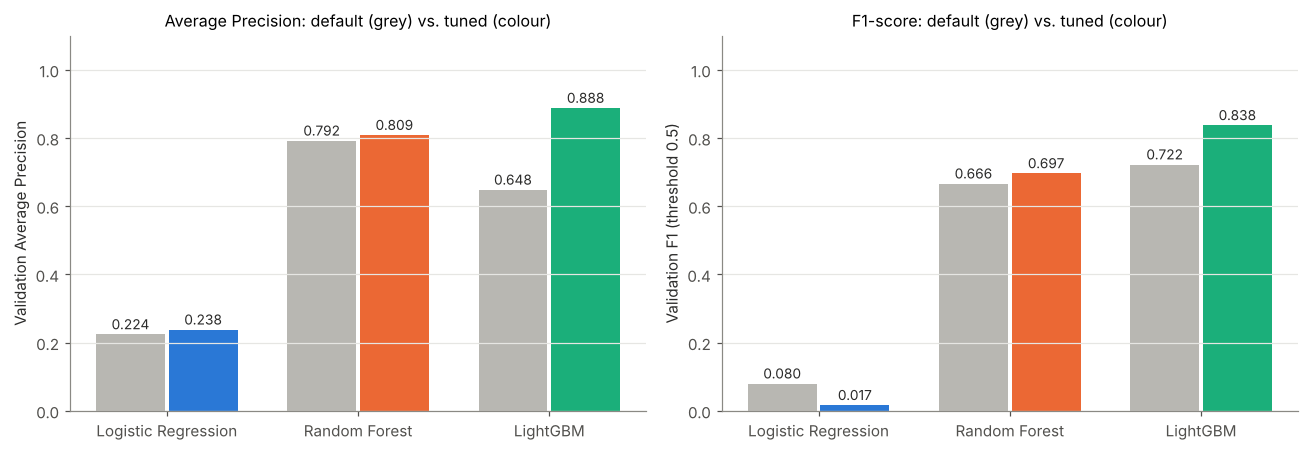

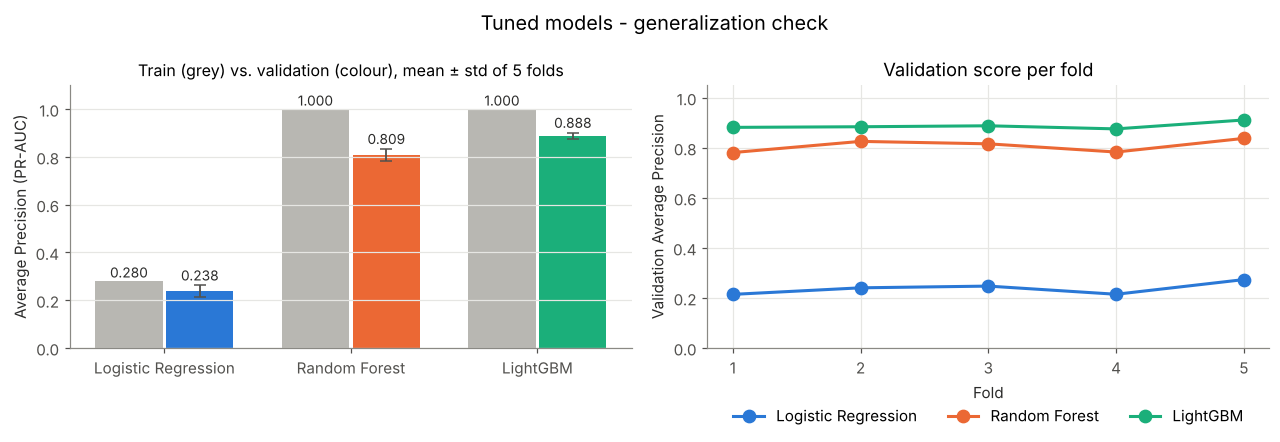

In [15]:
compare_rows = []
for name in default_pipelines:
    for version, res in [("Default", baseline_results[name]), ("Tuned", tuned_results[name])]:
        f = res["folds"]
        compare_rows.append({
            "Model": name, "Version": version,
            "val_AP_mean": f["val_avg_precision"].mean(), "val_AP_std": f["val_avg_precision"].std(),
            "val_ROC_AUC": f["val_roc_auc"].mean(), "val_F1": f["val_f1"].mean(),
            "val_Precision": f["val_precision"].mean(), "val_Recall": f["val_recall"].mean(),
            "train_AP": f["train_avg_precision"].mean(), "fit_time_s": f["fit_time_s"].mean(),
        })
default_vs_tuned = pd.DataFrame(compare_rows)
display(default_vs_tuned.round(4))
default_vs_tuned.to_csv(f"{OUTPUT_DIR}/default_vs_tuned.csv", index=False)

# Plot: default vs tuned main metric and F1
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
names = list(default_pipelines)
x = np.arange(len(names))
width = 0.36
for ax, metric, label in [(axes[0], "val_AP_mean", "Validation Average Precision"),
                          (axes[1], "val_F1", "Validation F1 (threshold 0.5)")]:
    d = default_vs_tuned[default_vs_tuned["Version"] == "Default"].set_index("Model").loc[names, metric]
    t = default_vs_tuned[default_vs_tuned["Version"] == "Tuned"].set_index("Model").loc[names, metric]
    ax.bar(x - width / 2 - 0.01, d, width, color="#b8b7b2")
    ax.bar(x + width / 2 + 0.01, t, width, color=[MODEL_COLORS[n] for n in names])
    for i in range(len(names)):
        ax.text(i - width / 2 - 0.01, d.iloc[i] + 0.015, f"{d.iloc[i]:.3f}", ha="center", fontsize=9, color="#2b2b2a")
        ax.text(i + width / 2 + 0.01, t.iloc[i] + 0.015, f"{t.iloc[i]:.3f}", ha="center", fontsize=9, color="#2b2b2a")
    ax.set_xticks(x, names)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Average Precision: default (grey) vs. tuned (colour)", fontsize=10.5)
axes[1].set_title("F1-score: default (grey) vs. tuned (colour)", fontsize=10.5)
fig.tight_layout()
plt.show()

plot_train_vs_val(tuned_results, "Tuned models - generalization check")

### 4.6 Interpretation of the Tuning Results

- **LightGBM benefits most:** AP rises from **0.648 ± 0.196** to **0.888 ± 0.014**. Fold-to-fold variation drops by more than ten times. The key changes were a smaller learning rate (~0.033) with more trees (800), `min_child_samples=100` (no leaves fitted to a handful of frauds), row/column subsampling, L2 regularisation and `scale_pos_weight=10` for the imbalance. F1 at 0.5 rises from 0.72 to 0.84.
- **Random Forest improves slightly:** AP rises from 0.792 to 0.809 with 200 trees and `max_features=0.03` (about 65 instead of about 46 features per split). Training AP stays at 1.0, so the forest still memorises the training data. Tuned fit time roughly doubles (~38 s per fold).
- **Logistic Regression stays weak:** the best `C` (~0.17, slightly stronger regularisation) gives a small AP gain (0.224 → 0.238). With `class_weight=None` at threshold 0.5 its recall is almost zero. The limit is the linear model family, not the hyperparameters.
- All comparisons use the same 5 folds and the same metric, and the test set was not used.

## 05 Metrics & Diagnostic Results

All diagnostics in this section use the **out-of-fold validation predictions** of the tuned models on the development sample (each prediction comes from a model that did not see that row). The test set is still untouched.

### 5.1 Classification Metrics

**Class imbalance:** only ~0.58 % of transactions are fraud. Accuracy is therefore shown but is not informative (a model that predicts "legitimate" for everything scores ~99.4 %). Precision (how many flagged transactions are truly fraud), Recall (how many frauds are caught), F1 (their harmonic mean) and the threshold-independent ROC-AUC and Average Precision are the meaningful metrics.

In [16]:
oof_metrics = pd.DataFrame({
    name: compute_metrics(y_dev, res["oof_proba"]) for name, res in tuned_results.items()
}).T
oof_metrics.columns = ["Avg Precision", "ROC-AUC", "F1", "Precision", "Recall", "Accuracy"]
display(oof_metrics.round(4))

for name, res in tuned_results.items():
    print(f"\n=== {name} (tuned, out-of-fold, threshold 0.5) ===")
    print(classification_report(y_dev, (res["oof_proba"] >= 0.5).astype(int),
                                target_names=["Legitimate", "Fraud"], digits=4))

,Avg Precision,ROC-AUC,F1,Precision,Recall,Accuracy
Logistic Regression,0.2361,0.8234,0.0167,0.1140,0.0090,0.9939
Random Forest,0.8085,0.9610,0.6971,0.9911,0.5377,0.9973
LightGBM,0.8882,0.9946,0.8377,0.8804,0.7989,0.9982



=== Logistic Regression (tuned, out-of-fold, threshold 0.5) ===
              precision    recall  f1-score   support

  Legitimate     0.9943    0.9996    0.9969    248553
       Fraud     0.1140    0.0090    0.0167      1447

    accuracy                         0.9939    250000
   macro avg     0.5541    0.5043    0.5068    250000
weighted avg     0.9892    0.9939    0.9912    250000


=== Random Forest (tuned, out-of-fold, threshold 0.5) ===


              precision    recall  f1-score   support

  Legitimate     0.9973    1.0000    0.9986    248553
       Fraud     0.9911    0.5377    0.6971      1447

    accuracy                         0.9973    250000
   macro avg     0.9942    0.7688    0.8479    250000
weighted avg     0.9973    0.9973    0.9969    250000


=== LightGBM (tuned, out-of-fold, threshold 0.5) ===
              precision    recall  f1-score   support

  Legitimate     0.9988    0.9994    0.9991    248553
       Fraud     0.8804    0.7989    0.8377      1447

    accuracy                         0.9982    250000
   macro avg     0.9396    0.8991    0.9184    250000
weighted avg     0.9981    0.9982    0.9982    250000



### 5.2 Confusion Matrices

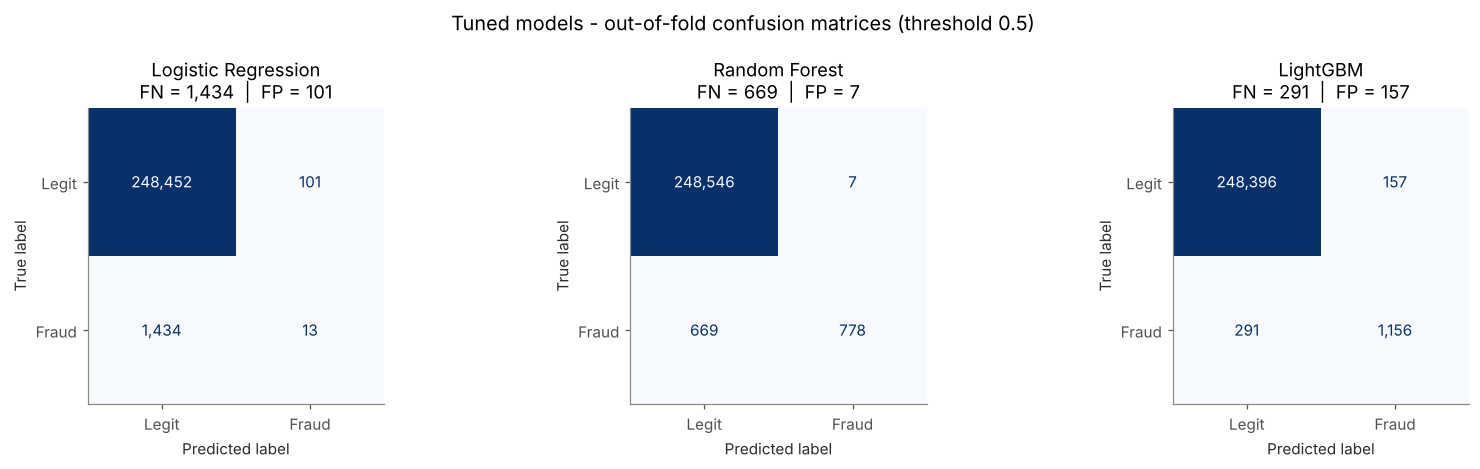

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, res) in zip(axes, tuned_results.items()):
    cm = confusion_matrix(y_dev, (res["oof_proba"] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(f"{name}\nFN = {cm[1, 0]:,}  |  FP = {cm[0, 1]:,}")
    ax.grid(False)
fig.suptitle("Tuned models - out-of-fold confusion matrices (threshold 0.5)", fontsize=13)
fig.tight_layout()
plt.show()

### 5.3 ROC and Precision–Recall Curves

The ROC curve can look very good on imbalanced data because the false-positive *rate* is divided by a huge number of negatives. The Precision–Recall curve is more informative here; the dashed line is the no-skill level (the fraud rate).

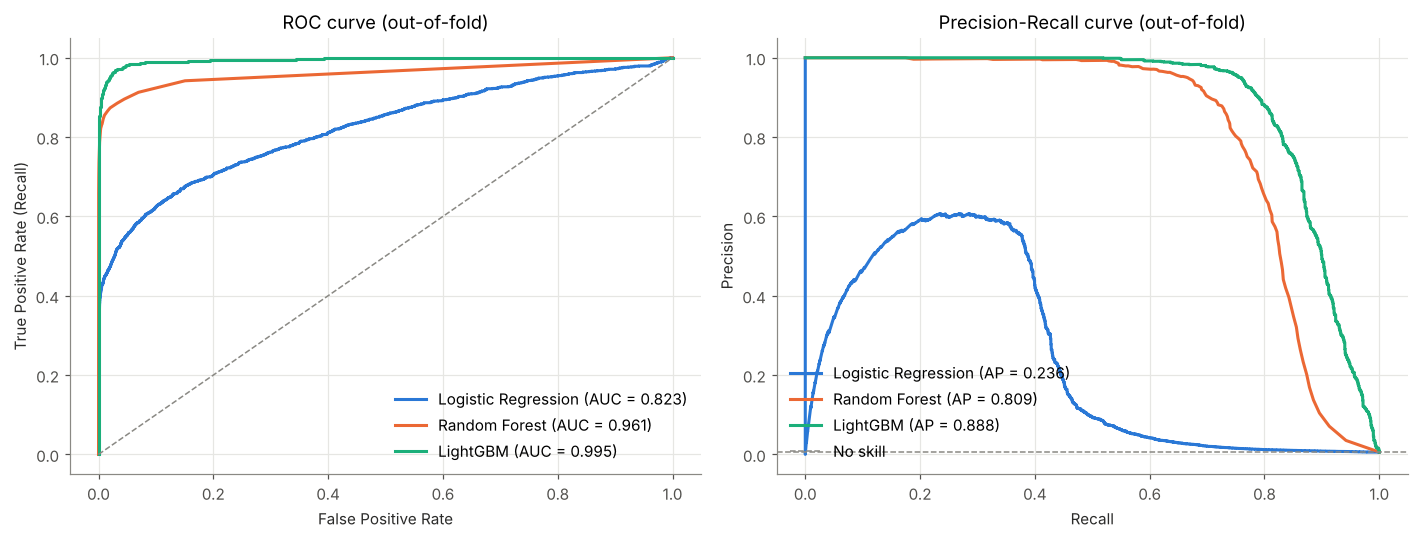

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, res in tuned_results.items():
    fpr, tpr, _ = roc_curve(y_dev, res["oof_proba"])
    prec, rec, _ = precision_recall_curve(y_dev, res["oof_proba"])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name],
                 label=f"{name} (AUC = {roc_auc_score(y_dev, res['oof_proba']):.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[name],
                 label=f"{name} (AP = {average_precision_score(y_dev, res['oof_proba']):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curve (out-of-fold)")
axes[0].legend(frameon=False, loc="lower right")

axes[1].axhline(y_dev.mean(), linestyle="--", color="#8a8984", linewidth=1, label="No skill")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve (out-of-fold)")
axes[1].legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

### 5.4 Interpretation of the Diagnostics

- **Accuracy is misleading:** all three models score above 99.3 %, including Logistic Regression, which misses over 99 % of frauds at threshold 0.5. This confirms the Task 1 finding that accuracy alone is not a suitable metric for this imbalanced problem.
- **ROC vs. PR:** Logistic Regression still reaches ROC-AUC ≈ 0.82, but its PR curve shows low precision at almost every recall level. The PR curve and Average Precision separate the models much more clearly than ROC-AUC.
- **Confusion matrices:** Random Forest produces very few false positives but misses roughly half of the frauds (high precision, low recall). Tuned LightGBM finds about 80 % of frauds while keeping precision near 88 %. It has the best balance, and its PR curve lies above the others over almost the whole recall range.

## 06 Compare & Select the Best Model

### 6.1 Final Comparison Table

One table with the default and tuned settings, the main validation metric (mean ± std over 5 folds), supporting metrics and training time for each model.

In [19]:
def fmt_params(params):
    return ", ".join(f"{k}={round(v, 4) if isinstance(v, float) else v}" for k, v in params.items())

comparison_rows = []
for name in default_pipelines:
    b, t = baseline_results[name]["folds"], tuned_results[name]["folds"]
    comparison_rows.append({
        "Model": name,
        "Default settings": fmt_params(baseline_settings[name]),
        "Tuned settings": fmt_params(tuned_settings[name]),
        "Default val AP (mean ± std)": f"{b['val_avg_precision'].mean():.4f} ± {b['val_avg_precision'].std():.4f}",
        "Tuned val AP (mean ± std)": f"{t['val_avg_precision'].mean():.4f} ± {t['val_avg_precision'].std():.4f}",
        "Tuned val ROC-AUC": round(t["val_roc_auc"].mean(), 4),
        "Tuned val F1": round(t["val_f1"].mean(), 4),
        "Tuned val Precision": round(t["val_precision"].mean(), 4),
        "Tuned val Recall": round(t["val_recall"].mean(), 4),
        "Tuned train AP": round(t["train_avg_precision"].mean(), 4),
        "Default fit time (s)": round(b["fit_time_s"].mean(), 2),
        "Tuned fit time (s)": round(t["fit_time_s"].mean(), 2),
        "Search time (min)": round(search_times[name] / 60, 1),
    })
comparison_table = pd.DataFrame(comparison_rows).set_index("Model")
comparison_table.to_csv(f"{OUTPUT_DIR}/model_comparison.csv")
display(comparison_table.T)

Model,Logistic Regression,Random Forest,LightGBM
Default settings,"C=1.0, class_weight=None, solver=lbfgs, max_it...","n_estimators=100, max_depth=None, min_samples_...","n_estimators=100, learning_rate=0.1, num_leave..."
Tuned settings,"C=0.1695, class_weight=None, solver=lbfgs, max...","n_estimators=200, max_depth=None, min_samples_...","n_estimators=800, learning_rate=0.0331, num_le..."
Default val AP (mean ± std),0.2243 ± 0.0269,0.7921 ± 0.0266,0.6483 ± 0.1955
Tuned val AP (mean ± std),0.2380 ± 0.0248,0.8087 ± 0.0255,0.8882 ± 0.0137
Tuned val ROC-AUC,0.8235,0.961,0.9946
Tuned val F1,0.0167,0.6965,0.8375
Tuned val Precision,0.1203,0.9911,0.8811
Tuned val Recall,0.009,0.5377,0.7989
Tuned train AP,0.2802,1.0,1.0
Default fit time (s),1.24,18.91,1.83


### 6.2 Choose the Winner

The winner is selected **only from cross-validation results on the training data**: the tuned model with the highest mean validation Average Precision. The fold standard deviation and the train–validation gap are checked as well, so that a model is not chosen because of one lucky fold. The held-out test set is not used for this decision.

In [20]:
selection = pd.DataFrame({
    name: {
        "val_AP_mean": r["folds"]["val_avg_precision"].mean(),
        "val_AP_std": r["folds"]["val_avg_precision"].std(),
        "train_val_gap": r["folds"]["train_avg_precision"].mean() - r["folds"]["val_avg_precision"].mean(),
        "val_F1_mean": r["folds"]["val_f1"].mean(),
        "fit_time_s": r["folds"]["fit_time_s"].mean(),
    } for name, r in tuned_results.items()
}).T.sort_values("val_AP_mean", ascending=False)
display(selection.round(4))

best_model_name = selection.index[0]
runner_up = selection.index[1]
margin = selection.loc[best_model_name, "val_AP_mean"] - selection.loc[runner_up, "val_AP_mean"]
print(f"Selected model: {best_model_name}")
print(f"Margin over runner-up ({runner_up}): {margin:.4f} AP "
      f"(= {margin / selection.loc[runner_up, 'val_AP_std']:.1f} x runner-up fold std)")

,val_AP_mean,val_AP_std,train_val_gap,val_F1_mean,fit_time_s
LightGBM,0.8882,0.0137,0.1118,0.8375,7.4740
Random Forest,0.8087,0.0255,0.1913,0.6965,38.0926
Logistic Regression,0.2380,0.0248,0.0422,0.0167,1.1482


Selected model: LightGBM
Margin over runner-up (Random Forest): 0.0795 AP (= 3.1 x runner-up fold std)


### 6.3 Justification of the Choice

**Selected model: tuned LightGBM.**

- **Best generalisation:** highest validation AP (**0.888**), ROC-AUC (0.995) and F1 (0.84). It beats the runner-up, Random Forest (0.809), by about 0.08 AP, roughly three times the Random Forest fold standard deviation, so the gap is not explained by fold noise.
- **Most stable:** lowest fold standard deviation (± 0.014) of all tuned models.
- **Over-fitting is controlled:** both tree models reach training AP 1.0, but LightGBM has the smaller train–validation gap (≈ 0.11 vs. ≈ 0.19 for Random Forest).
- **Performance–complexity trade-off:** LightGBM is also about 5× faster to train than the tuned Random Forest (≈ 7 s vs. ≈ 38 s per fold) and gives a much smaller model file. Logistic Regression is the fastest and simplest model, but its accuracy on frauds is far too low to justify that simplicity.

The decision is based only on cross-validation on the training data. The test set has still not been used.

### 6.4 Choose the Decision Threshold (training data only)

The default threshold of 0.5 is not necessarily the best operating point for an imbalanced problem. The threshold is chosen on the **out-of-fold validation predictions of the selected model** (training data only) as the threshold that maximises the fraud-class F1-score. It is fixed *before* the test set is evaluated.

Selected decision threshold: 0.7397


,avg_precision,roc_auc,f1,precision,recall,accuracy
Threshold 0.5,0.8882,0.9946,0.8377,0.8804,0.7989,0.9982
Threshold 0.740 (max F1),0.8882,0.9946,0.8445,0.9499,0.7602,0.9984


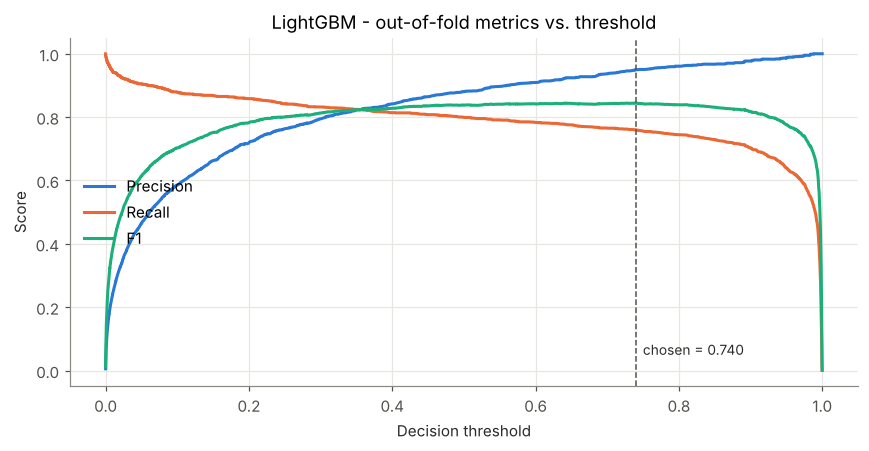

In [21]:
best_oof = tuned_results[best_model_name]["oof_proba"]
prec, rec, thr = precision_recall_curve(y_dev, best_oof)
f1_values = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_idx = int(np.nanargmax(f1_values))
DECISION_THRESHOLD = float(thr[best_idx])

threshold_table = pd.DataFrame({
    "Threshold 0.5": compute_metrics(y_dev, best_oof, 0.5),
    f"Threshold {DECISION_THRESHOLD:.3f} (max F1)": compute_metrics(y_dev, best_oof, DECISION_THRESHOLD),
}).T
print(f"Selected decision threshold: {DECISION_THRESHOLD:.4f}")
display(threshold_table.round(4))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(thr, prec[:-1], color="#2a78d6", label="Precision")
ax.plot(thr, rec[:-1], color="#eb6834", label="Recall")
ax.plot(thr, f1_values, color="#1baf7a", label="F1")
ax.axvline(DECISION_THRESHOLD, color="#52514e", linestyle="--", linewidth=1)
ax.text(DECISION_THRESHOLD + 0.01, 0.05, f"chosen = {DECISION_THRESHOLD:.3f}", color="#2b2b2a", fontsize=9)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title(f"{best_model_name} - out-of-fold metrics vs. threshold")
ax.legend(frameon=False, loc="center left")
fig.tight_layout()
plt.show()

## 07 Final Evaluation, Save & Reload

### 7.1 Final Fit on All Allowed Training Data

The selected tuned pipeline (preprocessing + model) is re-fitted on the **complete training file** (1,296,675 rows). The preprocessing is fitted on this training data only.

In [22]:
final_pipeline = clone(tuned_pipelines[best_model_name])

start = time.perf_counter()
final_pipeline.fit(X_train, y_train)
final_fit_time = time.perf_counter() - start

n_processed = final_pipeline.named_steps["preprocessor"].get_feature_names_out().shape[0]
print(f"Final model: {best_model_name}")
print(f"Trained on {X_train.shape[0]:,} rows, {X_train.shape[1]} input features "
      f"-> {n_processed:,} processed features")
print(f"Final fit time: {final_fit_time / 60:.2f} min")

Final model: LightGBM
Trained on 1,296,675 rows, 17 input features -> 2,159 processed features
Final fit time: 0.64 min


### 7.2 One-Time Evaluation on the Untouched Test Set

This is the **first and only** time the test set is used. The decision threshold selected in 6.4 is applied; metrics at the standard 0.5 threshold are shown for reference only (no choice is made from them).

In [23]:
start = time.perf_counter()
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
predict_time = time.perf_counter() - start
test_pred = (test_proba >= DECISION_THRESHOLD).astype(int)

test_metrics = compute_metrics(y_test, test_proba, DECISION_THRESHOLD)
test_metrics_05 = compute_metrics(y_test, test_proba, 0.5)

final_results = pd.DataFrame({
    f"Test (threshold {DECISION_THRESHOLD:.3f})": test_metrics,
    "Test (threshold 0.5, reference)": test_metrics_05,
    "CV validation (dev, mean)": {
        k: tuned_results[best_model_name]["folds"][f"val_{k}"].mean() for k in test_metrics
    },
}).T
display(final_results.round(4))
print(f"Prediction time for {len(X_test):,} test rows: {predict_time:.1f}s")

print(classification_report(y_test, test_pred, target_names=["Legitimate", "Fraud"], digits=4))

,avg_precision,roc_auc,f1,precision,recall,accuracy
Test (threshold 0.740),0.8444,0.9962,0.7978,0.8356,0.7632,0.9985
"Test (threshold 0.5, reference)",0.8444,0.9962,0.7222,0.6511,0.8107,0.9976
"CV validation (dev, mean)",0.8882,0.9946,0.8375,0.8811,0.7989,0.9982


Prediction time for 555,719 test rows: 8.2s


              precision    recall  f1-score   support

  Legitimate     0.9991    0.9994    0.9993    553574
       Fraud     0.8356    0.7632    0.7978      2145

    accuracy                         0.9985    555719
   macro avg     0.9174    0.8813    0.8985    555719
weighted avg     0.9985    0.9985    0.9985    555719



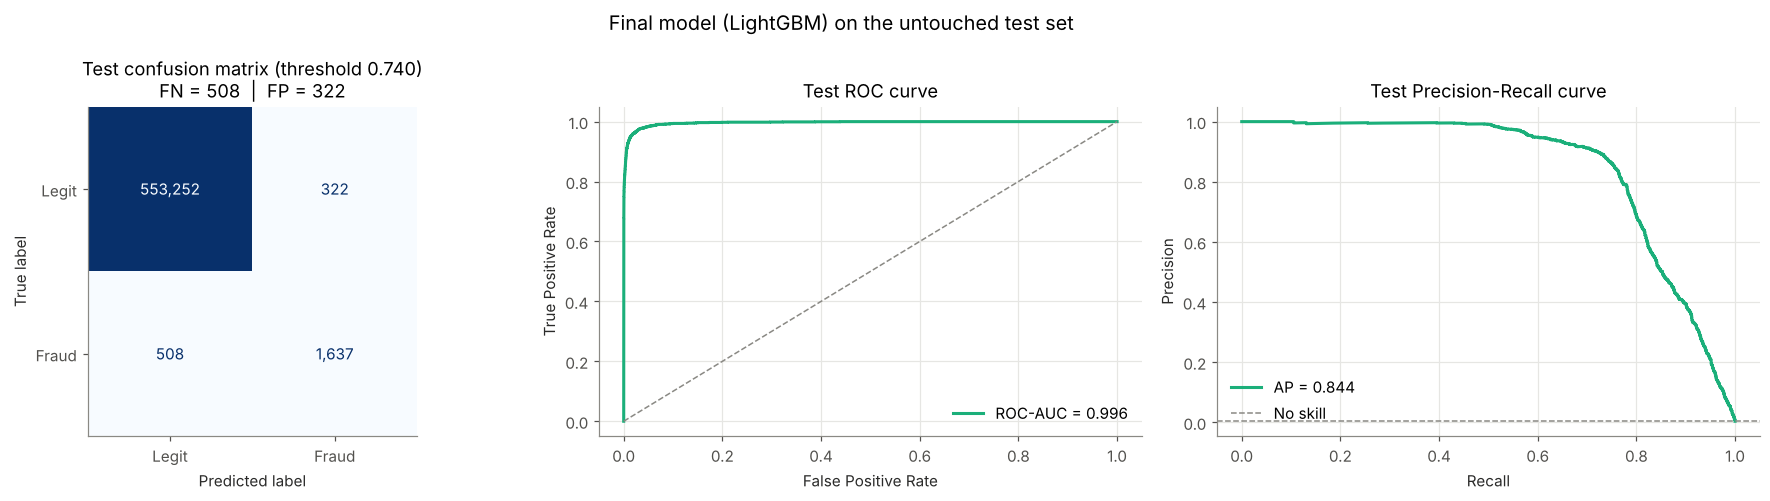

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title(f"Test confusion matrix (threshold {DECISION_THRESHOLD:.3f})\n"
                  f"FN = {cm[1, 0]:,}  |  FP = {cm[0, 1]:,}")
axes[0].grid(False)

color = MODEL_COLORS[best_model_name]
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=color, label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Test ROC curve")
axes[1].legend(frameon=False, loc="lower right")

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(r, p, color=color, label=f"AP = {test_metrics['avg_precision']:.3f}")
axes[2].axhline(y_test.mean(), linestyle="--", color="#8a8984", linewidth=1, label="No skill")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Test Precision-Recall curve")
axes[2].legend(frameon=False, loc="lower left")

fig.suptitle(f"Final model ({best_model_name}) on the untouched test set", fontsize=13)
fig.tight_layout()
plt.show()

### 7.3 Most Important Features of the Final Model

One-hot columns are summed back to their original feature so that the importance of e.g. `category` is shown as one bar. For LightGBM the total **gain** (loss reduction) is used; split counts would favour high-cardinality features with many one-hot columns. Importance shows what the model relies on, not causation.

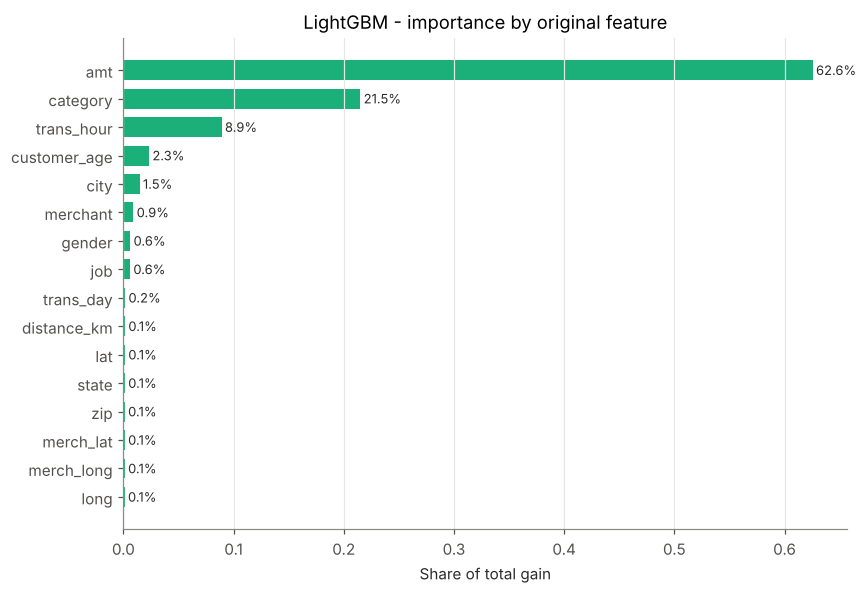

In [25]:
model_step = final_pipeline.named_steps["model"]
processed_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()

if hasattr(model_step, "booster_"):
    # LightGBM: total gain (split counts would favour features with many one-hot columns)
    raw_importance = model_step.booster_.feature_importance(importance_type="gain").astype(float)
    importance_label = "gain"
elif hasattr(model_step, "feature_importances_"):
    raw_importance = model_step.feature_importances_.astype(float)
    importance_label = "impurity importance"
else:
    raw_importance = np.abs(model_step.coef_[0])
    importance_label = "|coefficient|"


def original_feature(processed_name):
    """Map 'cat__category_grocery_pos' -> 'category', 'num__amt' -> 'amt'."""
    name = processed_name.split("__", 1)[1]
    for col in categorical_features:
        if name.startswith(col + "_"):
            return col
    return name


importance = (pd.DataFrame({"feature": [original_feature(n) for n in processed_names],
                            "importance": raw_importance})
              .groupby("feature")["importance"].sum())
importance = (importance / importance.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance.values, color=MODEL_COLORS[best_model_name], height=0.7)
for i, v in enumerate(importance.values):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", fontsize=8.5, color="#2b2b2a")
ax.set_xlabel(f"Share of total {importance_label}")
ax.set_title(f"{best_model_name} - importance by original feature")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### 7.4 Interpretation of the Final Test Results

- On the untouched test set (555,719 transactions, 2,145 frauds) the final LightGBM pipeline reaches **AP ≈ 0.844**, **ROC-AUC ≈ 0.996**, and at the pre-selected threshold (≈ 0.74) **precision ≈ 0.84, recall ≈ 0.76, F1 ≈ 0.80**. About **1,637 of 2,145 frauds are detected** with **322 false alarms** among more than 553,000 legitimate transactions.
- Test AP is a little lower than the CV estimate (0.888). This is expected: the test file covers a **later time period** (June–December 2020) than the training data, so some fraud patterns drift. The model was not changed after seeing these numbers.
- The threshold chosen on training data (≈ 0.74) trades a little recall for much higher precision than 0.5. The 0.5 row is shown for reference only.
- **Feature importance (gain):** the model relies mainly on **`amt` (≈ 63 %)**, **`category` (≈ 22 %)** and the engineered **`trans_hour` (≈ 9 %)**, followed by `customer_age` (≈ 2 %). This agrees with the Task 1 EDA findings that amount and category differ between fraud and legitimate transactions, and it shows that the Task 2 time feature adds value. Geographic coordinates and `distance_km` contribute very little.

### 7.5 Save the Model Pipeline and Metadata

Saved artifacts (folder `task3_output/`):

- `final_model_pipeline.joblib` - the complete fitted pipeline (Task 2 preprocessing + tuned model). It accepts the 17 Task 2 input features as a pandas DataFrame.
- `model_metadata.json` - model name, input feature names and types, processed feature names count, tuned hyperparameters, decision threshold, CV and test metrics, library versions and the inference method.
- CSV tables: research summary, baseline / tuned CV results, search results, default vs. tuned and the final comparison table.

In [26]:
MODEL_PATH = f"{OUTPUT_DIR}/final_model_pipeline.joblib"
METADATA_PATH = f"{OUTPUT_DIR}/model_metadata.json"

joblib.dump(final_pipeline, MODEL_PATH, compress=3)


def to_builtin(value):
    """Convert numpy types so that the metadata can be written as JSON."""
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    return value


best_cv = tuned_results[best_model_name]["folds"]
metadata = {
    "project": "Credit Card Fraud Detection - Task 3",
    "model_name": best_model_name,
    "model_class": type(final_pipeline.named_steps["model"]).__name__,
    "target": TARGET,
    "positive_class": "1 = fraud",
    "input_features": X_train.columns.tolist(),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "n_processed_features": int(n_processed),
    "dropped_raw_columns": DROP_COLUMNS,
    "engineered_features": ["trans_hour", "trans_day", "customer_age", "distance_km"],
    "hyperparameters": {k: to_builtin(v) for k, v in tuned_settings[best_model_name].items()},
    "decision_threshold": DECISION_THRESHOLD,
    "selection_metric": "average_precision (5-fold StratifiedKFold CV on 250,000-row training subsample)",
    "cv_metrics_mean": {k: float(best_cv[f"val_{k}"].mean()) for k in test_metrics},
    "cv_metrics_std": {k: float(best_cv[f"val_{k}"].std()) for k in test_metrics},
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "train_rows_final_fit": int(X_train.shape[0]),
    "final_fit_time_s": round(final_fit_time, 2),
    "library_versions": {"python": platform.python_version(), "pandas": pd.__version__,
                         "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
                         "joblib": joblib.__version__},
    "inference": ("raw transaction rows -> prepare_features() (Task 2 create_features + drop columns) "
                  "-> pipeline.predict_proba(X)[:, 1] -> fraud if probability >= decision_threshold"),
}
with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

for path in [MODEL_PATH, METADATA_PATH]:
    print(f"Saved {path} ({os.path.getsize(path) / 1024:,.1f} KB)")

Saved task3_output/final_model_pipeline.joblib (1,184.4 KB)
Saved task3_output/model_metadata.json (2.5 KB)


### 7.6 Reload Check

The saved artifacts are loaded **from disk** into new variables, and the reloaded pipeline is used on sample input.

**Inference method:**
1. Start from raw transaction rows with the same columns as `fraudTest.csv`.
2. Apply `prepare_features()` (the Task 2 feature engineering and column removal).
3. Call `pipeline.predict_proba(X)[:, 1]` to get the fraud probability (the pipeline applies imputation, scaling and one-hot encoding itself).
4. Flag the transaction as fraud if the probability is ≥ the saved `decision_threshold`.

In [27]:
# Load the artifacts from disk (independent of the in-memory objects above)
loaded_pipeline = joblib.load(MODEL_PATH)
with open(METADATA_PATH) as f:
    loaded_metadata = json.load(f)
threshold = loaded_metadata["decision_threshold"]

print("Loaded model    :", loaded_metadata["model_name"], "-", type(loaded_pipeline).__name__,
      [step for step, _ in loaded_pipeline.steps])
print("Input features  :", len(loaded_metadata["input_features"]))
print("Threshold       :", round(threshold, 4))

# Sample input: 5 legitimate + 5 fraudulent RAW test transactions
sample_raw = pd.concat([
    df_test[df_test[TARGET] == 0].sample(5, random_state=RANDOM_STATE),
    df_test[df_test[TARGET] == 1].sample(5, random_state=RANDOM_STATE),
])

# Inference: raw rows -> Task 2 features -> pipeline
sample_X = prepare_features(sample_raw).drop(columns=[TARGET])[loaded_metadata["input_features"]]
sample_proba = loaded_pipeline.predict_proba(sample_X)[:, 1]

sample_output = sample_raw[["trans_date_trans_time", "category", "amt", TARGET]].copy()
sample_output["fraud_probability"] = sample_proba.round(4)
sample_output["predicted_label"] = (sample_proba >= threshold).astype(int)
display(sample_output.reset_index(drop=True))

# The reloaded pipeline must reproduce the in-memory predictions exactly
check_rows = X_test.sample(2_000, random_state=RANDOM_STATE)
identical = np.allclose(loaded_pipeline.predict_proba(check_rows)[:, 1],
                        final_pipeline.predict_proba(check_rows)[:, 1])
print("Reloaded pipeline reproduces the original predictions:", identical)

Loaded model    : LightGBM - Pipeline ['preprocessor', 'model']
Input features  : 17
Threshold       : 0.7397


,trans_date_trans_time,category,amt,is_fraud,fraud_probability,predicted_label
0,2020-12-29 19:17:03,personal_care,60.51,0,0.0002,0
1,2020-12-26 03:46:04,shopping_pos,2.36,0,0.0000,0
2,2020-08-04 22:27:26,health_fitness,5.55,0,0.0001,0
3,2020-11-05 11:29:52,grocery_pos,115.80,0,0.0001,0
4,2020-08-24 12:08:18,food_dining,8.30,0,0.0002,0
5,2020-10-08 22:32:09,shopping_pos,798.05,1,0.9964,1
6,2020-12-05 22:09:52,personal_care,21.28,1,0.1397,0
7,2020-06-30 23:16:40,shopping_pos,917.97,1,0.9955,1
8,2020-07-20 03:05:54,grocery_net,8.39,1,0.8613,1
9,2020-09-27 03:14:02,shopping_net,1030.02,1,0.9565,1


Reloaded pipeline reproduces the original predictions: True


## Conclusion

- **Problem:** binary classification of credit-card fraud with severe class imbalance (≈ 0.58 % fraud). The main metric is Average Precision (PR-AUC).
- **Models researched and compared:** Logistic Regression (linear), Random Forest (bagging) and LightGBM (boosting). All use the same Task 2 preprocessing inside leakage-safe pipelines.
- **Validation:** stratified 5-fold CV on a 250,000-row stratified training subsample, with the same folds for every baseline and search. Results are reported as mean ± std, with train-vs-validation checks.
- **Tuning:** RandomizedSearchCV on training data only. LightGBM improved from 0.648 ± 0.196 to 0.888 ± 0.014 AP; Random Forest improved slightly; Logistic Regression is limited by its linear form.
- **Selected model:** tuned LightGBM, chosen from cross-validation evidence. It was re-fitted on all 1,296,675 training rows and evaluated **once** on the untouched test set: AP ≈ 0.84, ROC-AUC ≈ 0.996, F1 ≈ 0.80 at the training-selected threshold.
- **Deliverables:** the complete fitted pipeline (`task3_output/final_model_pipeline.joblib`) and its metadata (`task3_output/model_metadata.json`) were saved and successfully reloaded. The reloaded pipeline reproduces the original predictions.

### Submission Checklist

- [x] Runnable notebook with research summary and three documented model pipelines (Sections 01–02).
- [x] Default baselines, validation/CV output, tuning experiments, and suitable metrics/plots (Sections 02–05).
- [x] One comparison table with a justified best-model choice and final results (Sections 06–07).
- [x] Saved model/pipeline, required metadata, and a successful reload demonstration (Section 07).